In [ ]:
!pip install openpyxl -q

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [ ]:
!ls /content

'Online Retail.xlsx'   sample_data


In [ ]:
!wget -O online_retail.zip "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

--2026-10-29 14:02:04--  https://archive.ics.uci.edu/static/public/352/online+retail.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘online_retail.zip’

online_retail.zip       [      <=>           ]  22.62M  19.8MB/s    in 1.1s    

2026-10-29 14:02:06 (19.8 MB/s) - ‘online_retail.zip’ saved [23715478]



In [ ]:
!unzip -o online_retail.zip

Archive:  online_retail.zip
 extracting: Online Retail.xlsx      


In [ ]:
!ls

'Online Retail.xlsx'   online_retail.zip   sample_data


In [ ]:
!pip install openpyxl -q

In [ ]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [ ]:
df_raw = df.copy()
print("Avant nettoyage :", df.shape)

Avant nettoyage : (541909, 8)


In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [ ]:
df = df.dropna(subset=["CustomerID"])
print("Après suppression CustomerID manquants :", df.shape)

Après suppression CustomerID manquants : (406829, 8)


In [ ]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
print("Après suppression annulations :", df.shape)

Après suppression annulations : (397924, 8)


In [ ]:
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
print("Après suppression valeurs invalides :", df.shape)

Après suppression valeurs invalides : (397884, 8)


In [ ]:
print("Doublons :", df.duplicated().sum())
df = df.drop_duplicates()
print("Après suppression doublons :", df.shape)

Doublons : 5192
Après suppression doublons : (392692, 8)


In [ ]:
df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

In [ ]:
print(df.shape)
print("Clients uniques :", df["CustomerID"].nunique())
print("Période :", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
df.describe()

(392692, 9)
Clients uniques : 4338
Période : 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalPrice
count,392692.000000,392692,392692.000000,392692.000000,392692.000000
mean,13.119702,2011-07-10 19:13:07.771892480,3.125914,15287.843865,22.631500
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000
25%,2.000000,2011-04-07 11:12:00,1.250000,13955.000000,4.950000
50%,6.000000,2011-07-31 12:02:00,1.950000,15150.000000,12.450000
75%,12.000000,2011-10-20 12:53:00,3.750000,16791.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000,168469.600000
std,180.492832,NaN,22.241836,1713.539549,311.099224


In [ ]:
import datetime as dt

date_reference = df["InvoiceDate"].max() + dt.timedelta(days=1)
print("Date de référence :", date_reference)

Date de référence : 2011-12-10 12:50:00


In [ ]:
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (date_reference - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

print(rfm.shape)
rfm.head()

(4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [ ]:
rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.688081
std,1721.808492,100.014169,7.697998,8985.230220
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,306.482500
50%,15299.500000,51.000000,2.000000,668.570000
75%,16778.750000,142.000000,5.000000,1660.597500
max,18287.000000,374.000000,209.000000,280206.020000


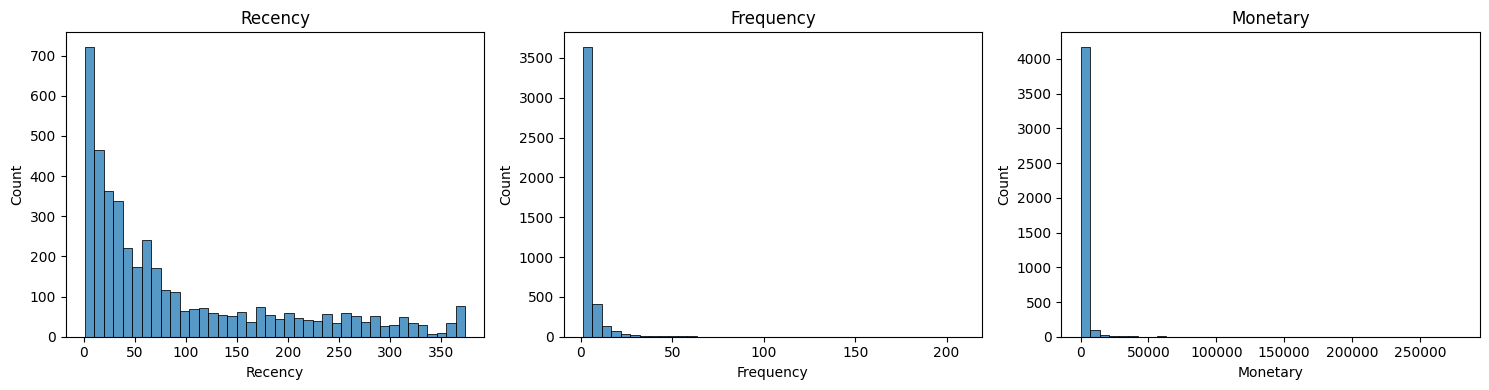

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [ ]:
rfm_log = rfm[["Recency", "Frequency", "Monetary"]].apply(np.log1p)
rfm_log.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,3.830734,1.345582,6.588562
std,1.340261,0.683104,1.258438
min,0.693147,0.693147,1.558145
25%,2.944439,0.693147,5.728418
50%,3.951244,1.098612,6.506636
75%,4.962845,1.791759,7.415535
max,5.926926,5.347108,12.543284


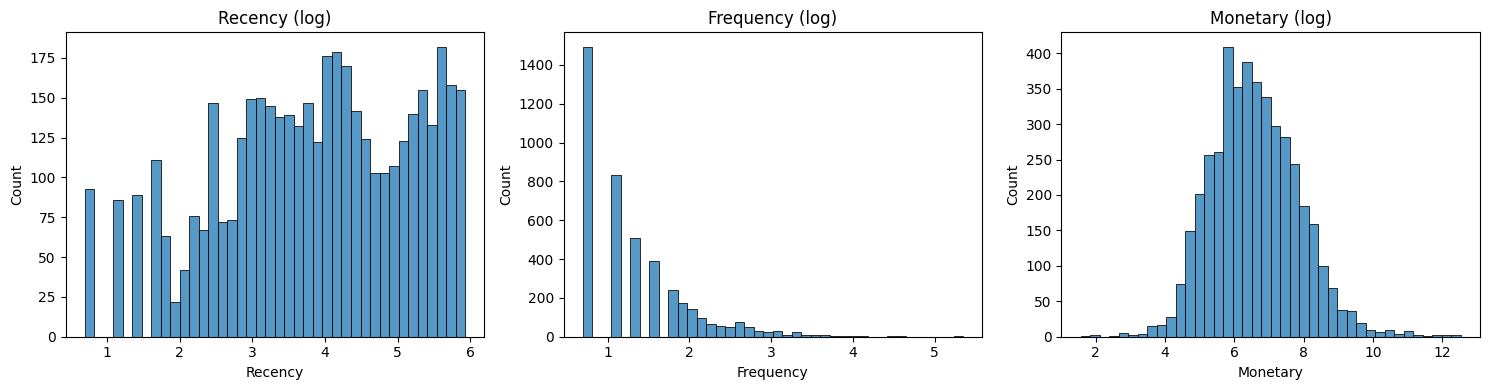

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm_log[col], bins=40, ax=ax)
    ax.set_title(col + " (log)")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"]
)
rfm_scaled_df.describe().round(2)

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-2.34,-0.96,-4.00
25%,-0.66,-0.96,-0.68
50%,0.09,-0.36,-0.07
75%,0.84,0.65,0.66
max,1.56,5.86,4.73


In [ ]:
print(rfm_scaled.shape)

(4338, 3)


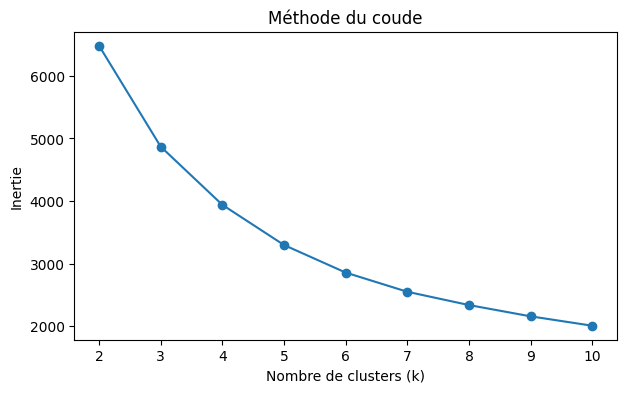

In [ ]:
from sklearn.cluster import KMeans

k_range = range(2, 11)
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_range, inertias, marker="o")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Inertie")
plt.title("Méthode du coude")
plt.xticks(list(k_range))
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(rfm_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled, labels))

resultats = pd.DataFrame({
    "k": list(k_range),
    "Inertie": inertias,
    "Silhouette": sil_scores
}).round(3)

resultats

,k,Inertie,Silhouette
0,2,6483.589,0.433
1,3,4869.489,0.337
2,4,3939.049,0.338
3,5,3296.709,0.316
4,6,2855.764,0.312
5,7,2548.820,0.309
6,8,2336.341,0.303
7,9,2156.006,0.281
8,10,2005.746,0.277


In [ ]:
K = 4

In [ ]:
kmeans_final = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=42)
kmeans_final.fit(rfm_scaled)

KMeans(n_clusters=4, n_init=10, random_state=42)

In [ ]:
rfm["Cluster"] = kmeans_final.labels_

print(rfm["Cluster"].value_counts().sort_index())
rfm.head()

Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,0
2,12348,75,4,1797.24,3
3,12349,19,1,1757.55,2
4,12350,310,1,334.40,1


In [ ]:
profil = rfm.groupby("Cluster").agg(
    Nb_clients=("CustomerID", "count"),
    Recency_moy=("Recency", "mean"),
    Frequency_moy=("Frequency", "mean"),
    Monetary_moy=("Monetary", "mean")
).round(1)

profil["Part_clients_%"] = (profil["Nb_clients"] / profil["Nb_clients"].sum() * 100).round(1)
profil

,Nb_clients,Recency_moy,Frequency_moy,Monetary_moy,Part_clients_%
Cluster,,,,,
0,713,12.2,13.8,8088.0,16.4
1,1622,181.5,1.3,341.0,37.4
2,837,17.7,2.2,557.3,19.3
3,1166,71.6,4.1,1801.8,26.9


In [ ]:
import plotly.express as px

fig = px.scatter_3d(
    rfm,
    x="Recency", y="Frequency", z="Monetary",
    color=rfm["Cluster"].astype(str),
    opacity=0.6,
    title="Segments clients (RFM)"
)
fig.update_traces(marker=dict(size=3))
fig.show()

In [ ]:
fig = px.scatter_3d(
    rfm_log.assign(Cluster=rfm["Cluster"].astype(str)),
    x="Recency", y="Frequency", z="Monetary",
    color="Cluster",
    opacity=0.6,
    title="Segments clients (RFM, échelle log)"
)
fig.update_traces(marker=dict(size=3))
fig.show()

In [ ]:
noms_segments = {
    0: "Clients VIP",
    1: "Clients à risque (churn)",
    2: "Nouveaux clients",
    3: "Clients fidèles"
}

rfm["Segment"] = rfm["Cluster"].map(noms_segments)
rfm["Segment"].value_counts()

,count
Segment,
Clients à risque (churn),1622
Clients fidèles,1166
Nouveaux clients,837
Clients VIP,713


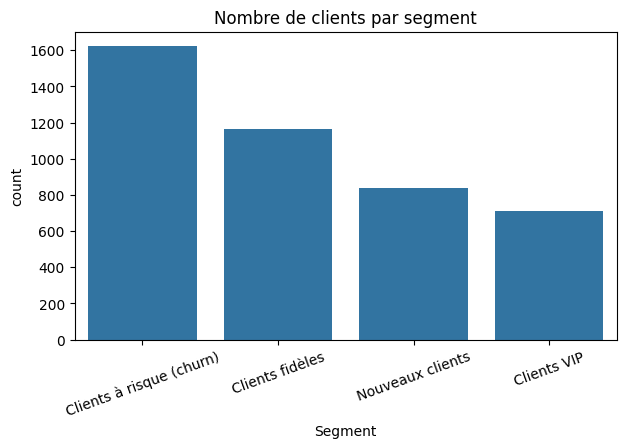

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=rfm, x="Segment", order=rfm["Segment"].value_counts().index)
plt.xticks(rotation=20)
plt.title("Nombre de clients par segment")
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

X_rfm = rfm[["Recency", "Frequency", "Monetary"]]

pipeline_rfm = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42))
])

pipeline_rfm.fit(X_rfm)

Pipeline(steps=[('log', FunctionTransformer(func=<ufunc 'log1p'>)),
                ('scaler', StandardScaler()),
                ('kmeans', KMeans(n_clusters=4, n_init=10, random_state=42))])

In [ ]:
labels_pipeline = pipeline_rfm.predict(X_rfm)
print("Mêmes clusters :", (labels_pipeline == rfm["Cluster"]).all())

Mêmes clusters : True


In [ ]:
import pickle

with open("modele_pipeline.pkl", "wb") as f:
    pickle.dump({"pipeline": pipeline_rfm, "segments": noms_segments}, f)

rfm.to_csv("rfm_segments.csv", index=False)

In [ ]:
with open("modele_pipeline.pkl", "rb") as f:
    modele = pickle.load(f)

exemple = pd.DataFrame({"Recency": [10], "Frequency": [15], "Monetary": [9000]})
cluster = modele["pipeline"].predict(exemple)[0]
print("Segment prédit :", modele["segments"][cluster])

Segment prédit : Clients VIP


In [ ]:
from google.colab import files
files.download("modele_pipeline.pkl")
files.download("rfm_segments.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1


In [ ]:
!pip install streamlit -q

In [ ]:
!ls

 modele_pipeline.pkl   online_retail.zip   sample_data
'Online Retail.xlsx'   rfm_segments.csv


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import pickle

st.set_page_config(page_title="Segmentation clients RFM", layout="wide")


@st.cache_resource
def charger_modele():
    with open("modele_pipeline.pkl", "rb") as f:
        return pickle.load(f)


modele = charger_modele()
pipeline = modele["pipeline"]
segments = modele["segments"]

st.title("Segmentation clients (RFM)")
st.write(
    "Cette application attribue un segment marketing à chaque client "
    "à partir de sa Récence, sa Fréquence et son Montant d'achats."
)
st.caption("Projet pédagogique : modèle entraîné sur le jeu de données UCI Online Retail.")

onglet1, onglet2 = st.tabs(["Simuler un client", "Importer un CSV"])

with onglet1:
    st.subheader("Simuler un client")
    c1, c2, c3 = st.columns(3)
    recency = c1.number_input("Récence (jours depuis le dernier achat)", min_value=0, value=30)
    frequency = c2.number_input("Fréquence (nombre de commandes)", min_value=1, value=3)
    monetary = c3.number_input("Montant total dépensé (£)", min_value=0.0, value=500.0)

    if st.button("Prédire le segment"):
        X = pd.DataFrame({
            "Recency": [recency],
            "Frequency": [frequency],
            "Monetary": [monetary],
        })
        cluster = pipeline.predict(X)[0]
        st.success(f"Segment prédit : {segments[cluster]}")

with onglet2:
    st.subheader("Segmenter un fichier de clients")
    st.write("Le fichier CSV doit contenir les colonnes : CustomerID, Recency, Frequency, Monetary.")

    fichier = st.file_uploader("Importer un fichier CSV", type="csv")

    if fichier is not None:
        data = pd.read_csv(fichier)
        colonnes = ["Recency", "Frequency", "Monetary"]
        manquantes = [c for c in colonnes if c not in data.columns]

        if manquantes:
            st.error(f"Colonnes manquantes : {', '.join(manquantes)}")
        elif (data[colonnes] < 0).any().any():
            st.error("Les colonnes Recency, Frequency et Monetary ne doivent pas contenir de valeurs négatives.")
        else:
            clusters = pipeline.predict(data[colonnes])
            data["Segment"] = [segments[c] for c in clusters]

            st.dataframe(data, use_container_width=True)
            st.bar_chart(data["Segment"].value_counts())

            st.download_button(
                "Télécharger les résultats",
                data.to_csv(index=False).encode("utf-8"),
                file_name="clients_segments.csv",
                mime="text/csv",
            )

Writing app.py


In [ ]:
import subprocess, time, re, os

if not os.path.exists("cloudflared"):
    subprocess.run(
        "wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared",
        shell=True
    )

subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
    stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT
)
time.sleep(6)

subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=open("tunnel.log", "w"), stderr=subprocess.STDOUT
)

for _ in range(20):
    time.sleep(2)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("tunnel.log").read())
    if m:
        print("Ton application :", m.group(0))
        break
else:
    print("Lien non trouvé, relance cette cellule dans quelques secondes.")

Lien non trouvé, relance cette cellule dans quelques secondes.


In [ ]:
from google.colab import files
files.download("rfm_segments.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Segmentation clients par RFM

Projet pédagogique de Machine Learning non supervisé : regrouper des clients d'une boutique en ligne selon leur comportement d'achat afin de personnaliser les actions marketing.

## Problème métier

Une entreprise e-commerce veut savoir qui sont ses meilleurs clients, lesquels risquent de partir et lesquels viennent d'arriver, pour adapter ses offres. Ce projet segmente les clients avec la méthode RFM :

- **Récence (R)** : nombre de jours depuis le dernier achat
- **Fréquence (F)** : nombre de commandes
- **Montant (M)** : total dépensé

## Données

- Jeu de données : **Online Retail** (UCI Machine Learning Repository)
- Transactions d'une boutique en ligne britannique entre décembre 2010 et décembre 2011
- 541 909 lignes brutes, 392 692 lignes après nettoyage, **4 338 clients**
- Les données ne sont pas incluses dans le dépôt : [lien de téléchargement](https://archive.ics.uci.edu/dataset/352/online+retail)

## Méthodologie

1. **Nettoyage** : suppression des lignes sans identifiant client, des annulations de facture, des quantités et prix négatifs ou nuls, et des doublons
2. **Calcul RFM** : une ligne par client
3. **Transformation** : logarithme (`log1p`) pour réduire l'asymétrie, puis `StandardScaler`
4. **Choix du nombre de clusters** : méthode du coude et score de silhouette, k = 4 retenu pour sa lisibilité métier
5. **Modèle** : K-Means, intégré dans un `Pipeline` scikit-learn (log, normalisation, K-Means) sauvegardé en `.pkl`
6. **Application** : interface Streamlit

## Résultats : 4 segments

| Segment | Part des clients | Récence moy. | Fréquence moy. | Montant moy. |
|---|---|---|---|---|
| Clients VIP | 16,4 % | 12 j | 13,8 | 8 088 £ |
| Clients fidèles | 26,9 % | 72 j | 4,1 | 1 802 £ |
| Nouveaux clients | 19,3 % | 18 j | 2,2 | 557 £ |
| Clients à risque (churn) | 37,4 % | 182 j | 1,3 | 341 £ |

## Application Streamlit

Deux fonctions : simuler un client à partir de sa R, F, M, ou importer un fichier CSV pour segmenter plusieurs clients et télécharger le résultat.

![Simulation d'un client VIP](captures/app_simulation_vip.png)
![Simulation d'un client à risque](captures/app_simulation_churn.png)
![Import d'un fichier CSV](captures/app_import_csv.png)

## Lancer le projet

```bash
pip install -r requirements.txt
streamlit run app.py
```

## Limites

- Projet pédagogique : les segments sont des profils statistiques, pas une décision commerciale validée.
- Les noms des segments ont été attribués après analyse des moyennes de chaque cluster.
- Un achat exceptionnel isolé (par exemple un client avec une seule commande très élevée) peut être classé dans un segment qui ne reflète pas son vrai comportement.
- Le modèle est entraîné sur une seule année de données d'une entreprise britannique.
- Le fichier `.pkl` doit être chargé avec la même version de scikit-learn (1.6.1).

## Auteure

Khadidiatou Lucia Sy Hodonou


In [1]:
!pip install openpyxl -q
!wget -q -O online_retail.zip "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
!unzip -o -q online_retail.zip

import pandas as pd
import numpy as np
import pickle
import datetime as dt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.cluster import KMeans
from google.colab import files

# Nettoyage
df = pd.read_excel("Online Retail.xlsx")
df = df.dropna(subset=["CustomerID"])
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df = df.drop_duplicates()
df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

# RFM
date_reference = df["InvoiceDate"].max() + dt.timedelta(days=1)
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (date_reference - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

# Pipeline
X_rfm = rfm[["Recency", "Frequency", "Monetary"]]
pipeline_rfm = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42))
])
pipeline_rfm.fit(X_rfm)
rfm["Cluster"] = pipeline_rfm.predict(X_rfm)

# Noms des segments attribués selon les moyennes
profil = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()
vip = profil["Monetary"].idxmax()
churn = profil["Recency"].idxmax()
reste = profil.drop([vip, churn])
nouveaux = reste["Recency"].idxmin()
fideles = [c for c in reste.index if c != nouveaux][0]

noms_segments = {
    int(vip): "Clients VIP",
    int(churn): "Clients à risque (churn)",
    int(nouveaux): "Nouveaux clients",
    int(fideles): "Clients fidèles",
}
rfm["Segment"] = rfm["Cluster"].map(noms_segments)

# Sauvegarde
with open("modele_pipeline.pkl", "wb") as f:
    pickle.dump({"pipeline": pipeline_rfm, "segments": noms_segments}, f)
rfm.to_csv("rfm_segments.csv", index=False)

# Vérifications
print("Clients :", rfm.shape[0])
print("Version scikit-learn :", sklearn.__version__)
print(profil.round(1).assign(Segment=profil.index.map(noms_segments)))

exemple = pd.DataFrame({"Recency": [10], "Frequency": [15], "Monetary": [9000]})
print("Test VIP :", noms_segments[pipeline_rfm.predict(exemple)[0]])

files.download("modele_pipeline.pkl")

Clients : 4338
Version scikit-learn : 1.6.1
         Recency  Frequency  Monetary                   Segment
Cluster                                                        
0           12.2       13.8    8088.0               Clients VIP
1          181.5        1.3     341.0  Clients à risque (churn)
2           17.7        2.2     557.3          Nouveaux clients
3           71.6        4.1    1801.8           Clients fidèles
Test VIP : Clients VIP


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>